# VALORA AI — Random Forest
**Modelling draft based on the professor’s `02_modelling` template.**

This is a separate, runnable experiment. Results are calculated after running the notebook; no test scores are assumed in advance.


## 1. TL;DR
This draft evaluates **Random Forest** against a simple mean-price baseline using held-out real apartment listings. Run the notebook to see the measured MAE, RMSE and R². Lower MAE is better.


## 2. Recap of the goal
Predict **advertised apartment asking prices in euros in Montenegro** from area, bedroom count and city. Success is measured primarily with mean absolute error (MAE), with RMSE and R² as supporting metrics. Asking prices are not verified sale prices.


## 3. Setup & data loading
Import the required libraries and load the previously cleaned dataset. In Google Colab, upload `valora_cleaned_step2.csv` when prompted. We filter to real online apartment listings to avoid synthetic data leakage.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from pathlib import Path

# In Colab upload valora_cleaned_step2.csv when requested.
path = Path('valora_cleaned_step2.csv')
if not path.exists():
    from google.colab import files
    uploaded = files.upload()
    path = Path('valora_cleaned_step2.csv')
    if not path.exists():
        raise FileNotFoundError('Please upload valora_cleaned_step2.csv')
df = pd.read_csv(path, low_memory=False)
print('Original dataset:', df.shape)

# Select real online apartment listings only; never train on synthetic examples.
required = ['property_type_clean','data_origin','data_source','price_eur','area_m2','sobe','city_clean']
missing = [c for c in required if c not in df.columns]
if missing: raise ValueError(f'Missing columns: {missing}')
real = df.loc[
    df['property_type_clean'].astype(str).str.strip().str.lower().eq('apartment') &
    df['data_origin'].astype(str).str.strip().str.upper().eq('REAL') &
    df['data_source'].astype(str).str.strip().eq('Online listing')
].copy()
real['price_eur'] = pd.to_numeric(real['price_eur'], errors='coerce')
real['area_m2'] = pd.to_numeric(real['area_m2'], errors='coerce')
real['bedrooms'] = pd.to_numeric(real['sobe'], errors='coerce')
real['city_model'] = real['city_clean'].fillna('Unknown').astype(str).str.strip().replace('', 'Unknown')
# Flag implausible listings for review; retain the same transparent rules in every draft.
real['price_per_m2_check'] = real['price_eur'] / real['area_m2'].replace(0, np.nan)
review_flags = real.loc[(real['price_eur'] < 10000) | (real['area_m2'] < 10) |
    (real['area_m2'] > 1000) | (real['price_per_m2_check'] < 300) |
    (real['price_per_m2_check'] > 15000)].copy()
clean = real.loc[(real['price_eur'] > 0) & (real['area_m2'] > 0) &
    np.isfinite(real['price_eur']) & np.isfinite(real['area_m2'])].copy()
print('Real apartments:',len(real),'| usable:',len(clean),'| review flags:',len(review_flags))
print('Unknown cities:',clean['city_model'].eq('Unknown').sum())


Original dataset: (4036, 48)
Real apartments: 1473 | usable: 1473 | review flags: 37
Unknown cities: 703


## 4. Feature preparation
Convert numerical inputs, fill missing bedroom values using training-only medians, and one-hot encode cities. Use only area, bedrooms and city for this experiment. Preprocessing is fitted inside a pipeline on training data only.


In [3]:
def add_features(frame):
    out = frame.copy()
    out['area_squared'] = out['area_m2'] ** 2
    out['area_per_bedroom'] = out['area_m2'] / out['bedrooms'].replace(0, np.nan)
    out['size_group'] = pd.cut(out['area_m2'], [0,50,100,np.inf], labels=['Small','Medium','Large']).astype('object').fillna('Unknown')
    return out

basic_num = ['area_m2','bedrooms']
basic_cat = ['city_model']
advanced_num = ['area_m2','bedrooms','area_squared','area_per_bedroom']
advanced_cat = ['city_model','size_group']
def processor(advanced=False):
    return ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), advanced_num if advanced else basic_num),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), advanced_cat if advanced else basic_cat)
    ])


## 5. Train/test split
Use a reproducible 80/20 split (`random_state=42`). The test set remains unseen during fitting and model selection. Results can be compared across these drafts only when the underlying data and filtering are identical.


In [4]:
# All drafts use the same fixed random split for a fair within-dataset comparison.
X = clean[['area_m2','bedrooms','city_model']].copy()
y = clean['price_eur'].copy()
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print('Train:',len(X_train),'Test:',len(X_test))


Train: 1178 Test: 295


## 6. Baseline model
Predict the mean training-set asking price for every test apartment. This intentionally simple benchmark shows whether machine learning improves on a constant prediction.


In [5]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train,y_train)
baseline_pred = baseline.predict(X_test)
print("Mean-price baseline MAE: €{:,.0f}".format(mean_absolute_error(y_test,baseline_pred)))


Mean-price baseline MAE: €107,905


## 7. Candidate models
Fit Random Forest. Keep the specified model settings fixed and do not tune on the test set.


In [6]:
X_train_model = add_features(X_train) if False else X_train
X_test_model = add_features(X_test) if False else X_test
model = Pipeline([("preprocess",processor()),("model",RandomForestRegressor(n_estimators=100,min_samples_leaf=2,random_state=42,n_jobs=-1))])
model.fit(X_train_model,y_train)
print("Random Forest trained.")


Random Forest trained.


## 8. Evaluation & comparison
Compare the baseline and candidate on the **same untouched test rows**. The table and chart are generated from actual model predictions, not manually entered results.


,Model,MAE (EUR),RMSE (EUR),R2
0,Mean-price baseline,107905.02,176181.71,-0.00
1,Random Forest,71129.13,137104.97,0.39


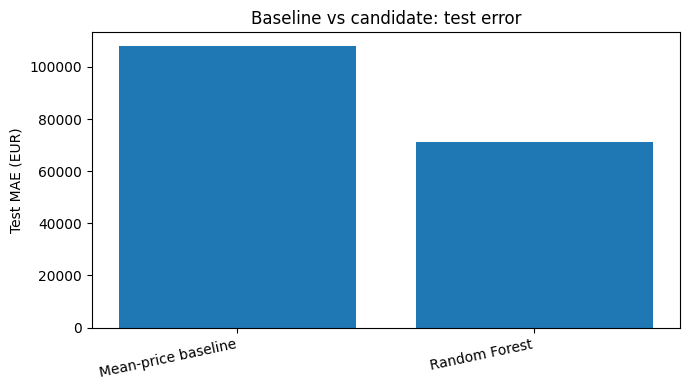

In [7]:
prediction = model.predict(X_test_model)
def scores(label,p):
    return {'Model':label,'MAE (EUR)':mean_absolute_error(y_test,p),
            'RMSE (EUR)':np.sqrt(mean_squared_error(y_test,p)),
            'R2':r2_score(y_test,p)}
results = pd.DataFrame([scores('Mean-price baseline',baseline_pred),scores('Random Forest',prediction)])
display(results.round(2))
plt.figure(figsize=(7,4))
plt.bar(results['Model'],results['MAE (EUR)'])
plt.ylabel('Test MAE (EUR)');plt.title('Baseline vs candidate: test error')
plt.xticks(rotation=12,ha='right');plt.tight_layout();plt.show()


## 9. Error analysis
Identify the largest absolute prediction errors and summarize results by city and price band. This helps explain where the model performs poorly, especially for luxury apartments and missing locations.


Largest prediction errors:


,area_m2,bedrooms,city_model,actual_eur,predicted_eur,absolute_error_eur,price_band
1293,100.0,2.0,Unknown,1300000.0,3.074553e+05,992544.704868,Over 1m
151,140.0,2.0,Unknown,1450000.0,6.179291e+05,832070.893651,Over 1m
110,164.0,2.0,Unknown,312500.0,1.019959e+06,707458.714286,300–500k
196,400.0,3.0,Unknown,950000.0,1.593273e+06,643272.619048,500k–1m
365,107.0,2.0,Tivat,949000.0,3.842787e+05,564721.309524,500k–1m
1433,99.0,NaN,Unknown,199000.0,6.802453e+05,481245.313199,100–200k
118,217.0,NaN,Unknown,850000.0,4.225175e+05,427482.452381,500k–1m
1431,99.0,NaN,Unknown,255000.0,6.802453e+05,425245.313199,200–300k
1252,80.0,1.0,Unknown,770000.0,3.900966e+05,379903.423009,500k–1m
1295,86.0,2.0,Unknown,650000.0,3.097305e+05,340269.497336,500k–1m


By asking-price band:


,count,mean
price_band,,
Under 100k,35,73257.0
100–200k,151,30957.0
200–300k,64,74131.0
300–500k,31,113025.0
500k–1m,12,305979.0
Over 1m,2,912308.0


By city:


,count,mean
city_model,,
Unknown,146,102387.0
Podgorica,96,27562.0
Ulcinj,14,47970.0
Tivat,11,123292.0
Kolasin,10,50104.0
Bar,7,62102.0
Budva,4,52660.0
Zabljak,3,26844.0
Kotor,2,42989.0


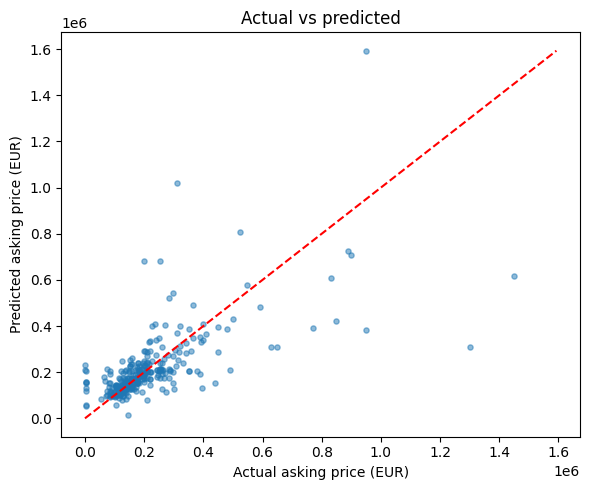

In [8]:
errors = X_test.copy()
errors['actual_eur'] = y_test
errors['predicted_eur'] = prediction
errors['absolute_error_eur'] = abs(errors['actual_eur']-errors['predicted_eur'])
errors['price_band'] = pd.cut(errors['actual_eur'],[0,100000,200000,300000,500000,1000000,np.inf],labels=['Under 100k','100–200k','200–300k','300–500k','500k–1m','Over 1m'])
print('Largest prediction errors:');display(errors.nlargest(10,'absolute_error_eur'))
print('By asking-price band:');display(errors.groupby('price_band',observed=True)['absolute_error_eur'].agg(['count','mean']).round(0))
print('By city:');display(errors.groupby('city_model')['absolute_error_eur'].agg(['count','mean']).sort_values('count',ascending=False).head(12).round(0))
plt.figure(figsize=(6,5));plt.scatter(y_test,prediction,alpha=.5,s=14)
limit=max(float(y_test.max()),float(np.max(prediction)))
plt.plot([0,limit],[0,limit],'r--');plt.xlabel('Actual asking price (EUR)');plt.ylabel('Predicted asking price (EUR)');plt.title('Actual vs predicted');plt.tight_layout();plt.show()


## 10. Interpretation
We examine how strongly each **input column** contributes to prediction performance using permutation importance on the test set. This is descriptive, not causal; correlated features may share importance.


,Increase in MAE when shuffled (EUR)
area_m2,72716.30
city_model,9206.96
bedrooms,4746.03


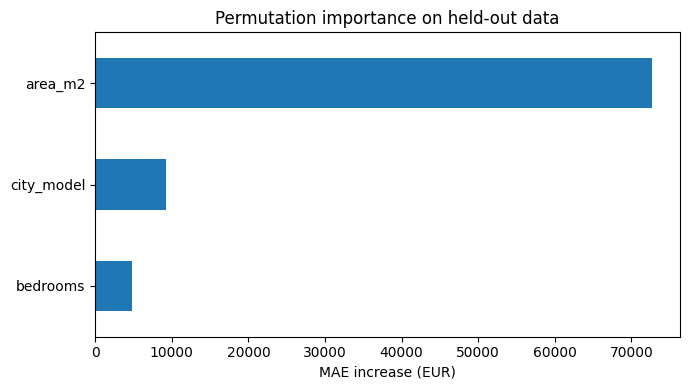

In [9]:
importance = permutation_importance(model,X_test_model,y_test,n_repeats=3,random_state=42,scoring='neg_mean_absolute_error')
feature_importance = pd.Series(importance.importances_mean,index=X_test_model.columns).sort_values(ascending=False)
display(feature_importance.to_frame('Increase in MAE when shuffled (EUR)').round(2))
plt.figure(figsize=(7,4));feature_importance.sort_values().plot.barh()
plt.xlabel('MAE increase (EUR)');plt.title('Permutation importance on held-out data');plt.tight_layout();plt.show()


## 11. Limitations & ethics
The model learns from **advertised asking prices**, not completed sales or professional appraisals. Online listings may contain errors, duplicates and missing neighborhoods. Premium apartments are especially hard to predict without property condition, sea views and precise location. The test data were used for reporting and should not be repeatedly used to choose models. Predictions should not be presented as official valuations.


## 12. Conclusion & next steps
This notebook documents Random Forest with a reproducible baseline, held-out evaluation, error analysis and interpretation. After running it, use the measured results in Section 8 to state whether this candidate improves on the baseline. A future project could add verified transaction prices, more detailed location features, and a new independent evaluation dataset.
